<a href="https://colab.research.google.com/github/rithishacs24-lab/BIS-LAB/blob/main/Genetic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting Genetic Algorithm...

Generation 0: Best Fitness = 5.847953
Generation 25: Best Fitness = 40.000000
Generation 50: Best Fitness = 47.619048
Generation 75: Best Fitness = 52.631579
Generation 100: Best Fitness = 76.923077
Generation 125: Best Fitness = 76.923077
Generation 150: Best Fitness = 76.923077
Generation 175: Best Fitness = 90.909091
Generation 200: Best Fitness = 90.909091
Generation 225: Best Fitness = 90.909091
Generation 250: Best Fitness = 90.909091
Generation 275: Best Fitness = 90.909091

Optimization completed!
Best Fitness Score: 90.909091

========== OPTIMIZED WEEKLY SCHEDULE ==========

      Day                Morning                 Evening                   Night
   Monday Employee_7, Employee_4 Employee_10, Employee_5  Employee_3, Employee_6
  Tuesday Employee_4, Employee_1  Employee_2, Employee_9 Employee_10, Employee_8
Wednesday Employee_7, Employee_9  Employee_5, Employee_2  Employee_8, Employee_3
 Thursday Employee_4, Employee_1  Employee_9, Employee

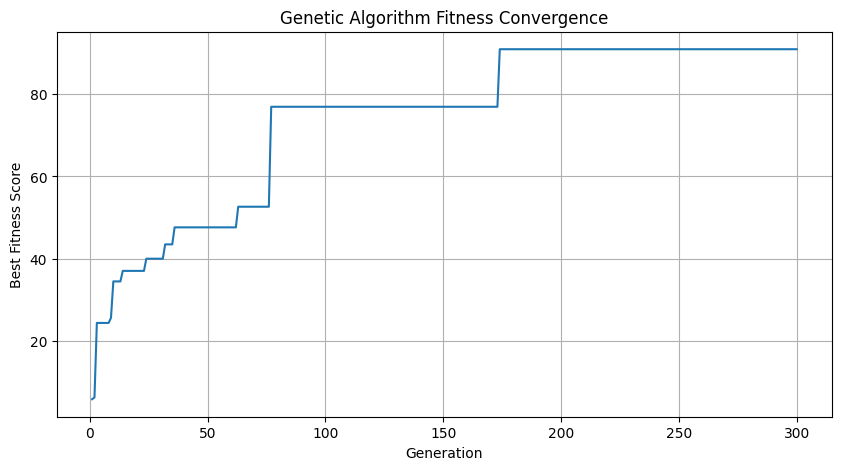

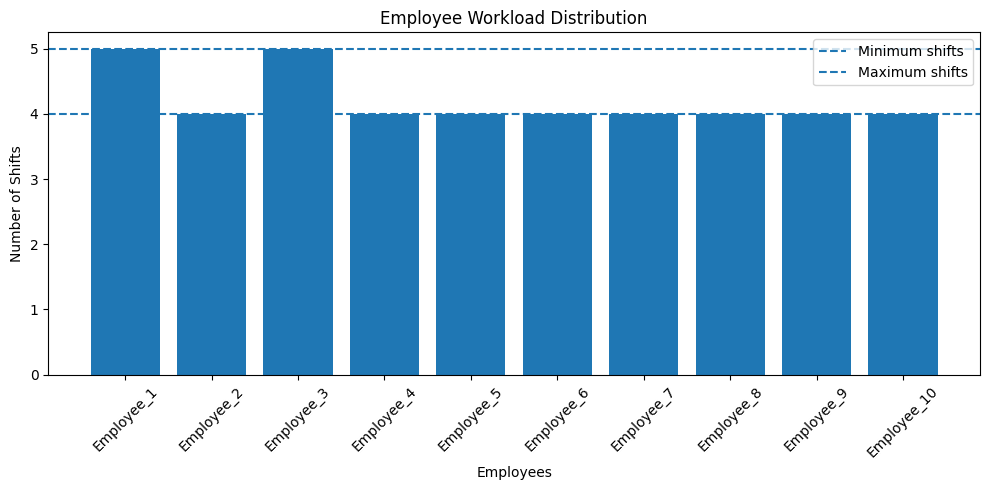


Excel file generated successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# GENETIC ALGORITHM: EMPLOYEE SHIFT SCHEDULING OPTIMIZATION
# Google Colab Implementation
# ============================================================

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. PROBLEM CONFIGURATION
# ------------------------------------------------------------

random.seed(42)
np.random.seed(42)

employees = [
    "Employee_1", "Employee_2", "Employee_3",
    "Employee_4", "Employee_5", "Employee_6",
    "Employee_7", "Employee_8", "Employee_9",
    "Employee_10"
]

days = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

shifts = ["Morning", "Evening", "Night"]

EMPLOYEE_COUNT = len(employees)
DAYS_COUNT = len(days)
SHIFTS_COUNT = len(shifts)

EMPLOYEES_PER_SHIFT = 2

POPULATION_SIZE = 100
GENERATIONS = 300
MUTATION_RATE = 0.10
TOURNAMENT_SIZE = 5
ELITISM = 2

MIN_SHIFTS = 4
MAX_SHIFTS = 5

# Employee shift preferences
preferences = {
    "Employee_1": ["Morning"],
    "Employee_2": ["Evening"],
    "Employee_3": ["Night"],
    "Employee_4": ["Morning", "Evening"],
    "Employee_5": ["Evening"],
    "Employee_6": ["Night"],
    "Employee_7": ["Morning"],
    "Employee_8": ["Morning", "Night"],
    "Employee_9": ["Evening"],
    "Employee_10": ["Night", "Evening"]
}

# Each chromosome has 7 * 3 * 2 = 42 genes.
# Each gene represents one employee assigned to one shift position.

GENOME_LENGTH = DAYS_COUNT * SHIFTS_COUNT * EMPLOYEES_PER_SHIFT


# ------------------------------------------------------------
# 2. CHROMOSOME REPAIR
# Ensures an employee cannot work multiple shifts on one day.
# ------------------------------------------------------------

def repair_chromosome(chromosome):

    repaired = chromosome.copy()
    weekly_workload = [0] * EMPLOYEE_COUNT

    for day in range(DAYS_COUNT):

        used_employees = set()

        start = day * SHIFTS_COUNT * EMPLOYEES_PER_SHIFT
        end = start + SHIFTS_COUNT * EMPLOYEES_PER_SHIFT

        for position in range(start, end):

            employee = repaired[position]

            # Replace duplicate daily assignments
            if employee in used_employees:

                candidates = [
                    e for e in range(EMPLOYEE_COUNT)
                    if e not in used_employees
                ]

                # Prefer employees with fewer shifts
                employee = min(
                    candidates,
                    key=lambda e: (
                        weekly_workload[e],
                        0 if shifts[position % (
                            SHIFTS_COUNT * EMPLOYEES_PER_SHIFT
                        ) // EMPLOYEES_PER_SHIFT]
                        in preferences[employees[e]] else 1,
                        random.random()
                    )
                )

                repaired[position] = employee

            used_employees.add(employee)
            weekly_workload[employee] += 1

    return repaired


# ------------------------------------------------------------
# 3. INITIAL POPULATION
# ------------------------------------------------------------

def create_chromosome():

    chromosome = []

    for day in range(DAYS_COUNT):

        # Six different employees per day
        daily_employees = random.sample(
            range(EMPLOYEE_COUNT),
            SHIFTS_COUNT * EMPLOYEES_PER_SHIFT
        )

        chromosome.extend(daily_employees)

    return chromosome


def create_population():

    return [
        create_chromosome()
        for _ in range(POPULATION_SIZE)
    ]


# ------------------------------------------------------------
# 4. FITNESS FUNCTION
# ------------------------------------------------------------

def fitness(chromosome):

    workload = [0] * EMPLOYEE_COUNT
    preference_penalty = 0

    for day in range(DAYS_COUNT):

        start = day * SHIFTS_COUNT * EMPLOYEES_PER_SHIFT

        for shift in range(SHIFTS_COUNT):

            for position in range(EMPLOYEES_PER_SHIFT):

                index = (
                    start +
                    shift * EMPLOYEES_PER_SHIFT +
                    position
                )

                employee_index = chromosome[index]

                workload[employee_index] += 1

                employee_name = employees[employee_index]
                shift_name = shifts[shift]

                # Penalty for ignoring employee preference
                if shift_name not in preferences[employee_name]:
                    preference_penalty += 1

    # Penalize workload outside the desired range
    workload_penalty = sum(
        max(0, MIN_SHIFTS - count) ** 2 +
        max(0, count - MAX_SHIFTS) ** 2
        for count in workload
    )

    # Penalize unequal workload distribution
    average_workload = GENOME_LENGTH / EMPLOYEE_COUNT

    fairness_penalty = sum(
        (count - average_workload) ** 2
        for count in workload
    )

    total_penalty = (
        100 * workload_penalty +
        5 * fairness_penalty +
        2 * preference_penalty
    )

    return 1000 / (1 + total_penalty)


# ------------------------------------------------------------
# 5. SELECTION: TOURNAMENT SELECTION
# ------------------------------------------------------------

def selection(population):

    competitors = random.sample(
        population,
        TOURNAMENT_SIZE
    )

    return max(competitors, key=fitness).copy()


# ------------------------------------------------------------
# 6. CROSSOVER: ONE-POINT CROSSOVER
# ------------------------------------------------------------

def crossover(parent1, parent2):

    point = random.randint(1, GENOME_LENGTH - 1)

    child1 = parent1[:point] + parent2[point:]
    child2 = parent2[:point] + parent1[point:]

    return (
        repair_chromosome(child1),
        repair_chromosome(child2)
    )


# ------------------------------------------------------------
# 7. MUTATION
# ------------------------------------------------------------

def mutation(chromosome):

    mutated = chromosome.copy()

    for day in range(DAYS_COUNT):

        for shift in range(SHIFTS_COUNT):

            for position in range(EMPLOYEES_PER_SHIFT):

                if random.random() < MUTATION_RATE:

                    index = (
                        day * SHIFTS_COUNT * EMPLOYEES_PER_SHIFT
                        + shift * EMPLOYEES_PER_SHIFT
                        + position
                    )

                    mutated[index] = random.randint(
                        0, EMPLOYEE_COUNT - 1
                    )

    return repair_chromosome(mutated)


# ------------------------------------------------------------
# 8. GENETIC ALGORITHM
# ------------------------------------------------------------

def genetic_algorithm():

    population = create_population()

    best_scores = []
    best_chromosome = None
    best_score = -1

    for generation in range(GENERATIONS):

        population.sort(
            key=fitness,
            reverse=True
        )

        current_best = population[0]
        current_score = fitness(current_best)

        if current_score > best_score:

            best_score = current_score
            best_chromosome = current_best.copy()

        best_scores.append(best_score)

        # Elitism: retain the best individuals
        new_population = [
            individual.copy()
            for individual in population[:ELITISM]
        ]

        while len(new_population) < POPULATION_SIZE:

            parent1 = selection(population)
            parent2 = selection(population)

            child1, child2 = crossover(parent1, parent2)

            child1 = mutation(child1)
            child2 = mutation(child2)

            new_population.append(child1)

            if len(new_population) < POPULATION_SIZE:
                new_population.append(child2)

        population = new_population

        if generation % 25 == 0:
            print(
                f"Generation {generation}: "
                f"Best Fitness = {best_score:.6f}"
            )

    return best_chromosome, best_scores


# ------------------------------------------------------------
# 9. RUN THE ALGORITHM
# ------------------------------------------------------------

print("Starting Genetic Algorithm...\n")

best_schedule, fitness_history = genetic_algorithm()

print("\nOptimization completed!")
print("Best Fitness Score:", round(fitness(best_schedule), 6))


# ------------------------------------------------------------
# 10. GENERATE WEEKLY SCHEDULE
# ------------------------------------------------------------

schedule_data = []

for day in range(DAYS_COUNT):

    row = {"Day": days[day]}

    for shift in range(SHIFTS_COUNT):

        start = (
            day * SHIFTS_COUNT * EMPLOYEES_PER_SHIFT
            + shift * EMPLOYEES_PER_SHIFT
        )

        assigned = [
            employees[best_schedule[start + i]]
            for i in range(EMPLOYEES_PER_SHIFT)
        ]

        row[shifts[shift]] = ", ".join(assigned)

    schedule_data.append(row)

schedule_df = pd.DataFrame(schedule_data)

print("\n========== OPTIMIZED WEEKLY SCHEDULE ==========\n")
print(schedule_df.to_string(index=False))


# ------------------------------------------------------------
# 11. EMPLOYEE WORKLOAD ANALYSIS
# ------------------------------------------------------------

workload = [0] * EMPLOYEE_COUNT

for employee_index in best_schedule:
    workload[employee_index] += 1

workload_df = pd.DataFrame({
    "Employee": employees,
    "Total Shifts": workload,
    "Minimum Required": [MIN_SHIFTS] * EMPLOYEE_COUNT,
    "Maximum Required": [MAX_SHIFTS] * EMPLOYEE_COUNT
})

print("\n========== EMPLOYEE WORKLOAD ==========\n")
print(workload_df.to_string(index=False))


# ------------------------------------------------------------
# 12. VALIDATION
# ------------------------------------------------------------

def validate_schedule(chromosome):

    valid = True

    for day in range(DAYS_COUNT):

        start = day * SHIFTS_COUNT * EMPLOYEES_PER_SHIFT

        daily_assignments = chromosome[
            start:start + SHIFTS_COUNT * EMPLOYEES_PER_SHIFT
        ]

        if len(set(daily_assignments)) != len(daily_assignments):
            print("ERROR: Employee assigned multiple shifts:", days[day])
            valid = False

    for i, count in enumerate(workload):

        if count < MIN_SHIFTS or count > MAX_SHIFTS:
            print(
                f"WARNING: {employees[i]} has {count} shifts."
            )
            valid = False

    if valid:
        print("SUCCESS: All scheduling constraints satisfied.")

    return valid


print("\n========== SCHEDULE VALIDATION ==========\n")

is_valid = validate_schedule(best_schedule)


# ------------------------------------------------------------
# 13. FITNESS CONVERGENCE GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, GENERATIONS + 1),
    fitness_history
)

plt.title("Genetic Algorithm Fitness Convergence")
plt.xlabel("Generation")
plt.ylabel("Best Fitness Score")
plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 14. EMPLOYEE WORKLOAD GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(employees, workload)

plt.axhline(
    MIN_SHIFTS,
    linestyle="--",
    label="Minimum shifts"
)

plt.axhline(
    MAX_SHIFTS,
    linestyle="--",
    label="Maximum shifts"
)

plt.title("Employee Workload Distribution")
plt.xlabel("Employees")
plt.ylabel("Number of Shifts")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 15. EXPORT RESULTS TO EXCEL
# ------------------------------------------------------------

with pd.ExcelWriter("Employee_Shift_Schedule.xlsx") as writer:

    schedule_df.to_excel(
        writer,
        sheet_name="Weekly Schedule",
        index=False
    )

    workload_df.to_excel(
        writer,
        sheet_name="Employee Workload",
        index=False
    )

print("\nExcel file generated successfully!")

# Download the Excel file in Google Colab
from google.colab import files

files.download("Employee_Shift_Schedule.xlsx")